# **Pizza and Ice Cream Image Classification using CNN**

In [1]:
!pip install --upgrade --quiet keras-hub keras

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Built-in Python libraries
import os
import shutil
import datetime

# Dataset downloading
import kagglehub

# Deep learning frameworks
import keras
import keras_hub
import tensorflow as tf

# Model building
from keras.models import Sequential

# CNN layers
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense,Input,BatchNormalization,Dropout

# Training callbacks
from keras.callbacks import EarlyStopping, ModelCheckpoint


# Download the Dataset from Kaggle

In [4]:
# Download latest version
path = kagglehub.dataset_download("hemendrasr/pizza-vs-ice-cream")

print("Path to dataset files:", path)

100%|██████████| 41.7M/41.7M [00:00<00:00, 212MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hemendrasr/pizza-vs-ice-cream/versions/9


In [5]:
# download dataset to colab
!kaggle datasets download -d hemendrasr/pizza-vs-ice-cream

Dataset URL: https://www.kaggle.com/datasets/hemendrasr/pizza-vs-ice-cream
License(s): other
100% 41.7M/41.7M [00:00<00:00, 261MB/s]



In [6]:
# Unzip dataset
!unzip '/content/pizza-vs-ice-cream.zip'

Archive:  /content/pizza-vs-ice-cream.zip
  inflating: README.md               
  inflating: dataset/test/icecream/00110_jpg.rf.8e2342aa2d175b85bdc6dd27649f3f99.jpg  
  inflating: dataset/test/icecream/00119_jpg.rf.814e5835e122b325ffc49f2671f6b7f0.jpg  
  inflating: dataset/test/icecream/00124_jpg.rf.cbfd9b294fb345cac66fea8d648861dd.jpg  
  inflating: dataset/test/icecream/00126_jpg.rf.d8bd0dacaa776c92bac0f6087c81a58f.jpg  
  inflating: dataset/test/icecream/00132_jpg.rf.403736aa08b4664e66095811823d6ea3.jpg  
  inflating: dataset/test/icecream/00146_jpg.rf.c9421eb0b6eb46d80fdc889f2d18af1e.jpg  
  inflating: dataset/test/icecream/00160_jpg.rf.cceaa1e6eeff7e4eafa742eb75ec9be4.jpg  
  inflating: dataset/test/icecream/00180_jpg.rf.dbfe23770ca6f1457e52b6a99806b1ee.jpg  
  inflating: dataset/test/icecream/00190_jpg.rf.9f24ad985e14ceebd07dfe8799a4c01e.jpg  
  inflating: dataset/test/icecream/00191_jpg.rf.c626d6b25ee22b84526811701b80c117.jpg  
  inflating: dataset/test/icecream/00196_jpg.rf.2a

In [7]:
# Define the dataset directory
dataset_test = '/content/test'
dataset_train = '/content/train'

In [8]:
# Training + validation datasets
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    directory='dataset/train',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    seed=42,
    subset='both',
    validation_split=0.2,
)
# Test dataset
test_ds = keras.utils.image_dataset_from_directory(
    directory='dataset/test',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224)
)

Found 718 files belonging to 2 classes.
Using 575 files for training.
Using 143 files for validation.
Found 106 files belonging to 2 classes.


In [9]:
print("Class Names:", train_ds.class_names)

Class Names: ['icecream', 'pizza']


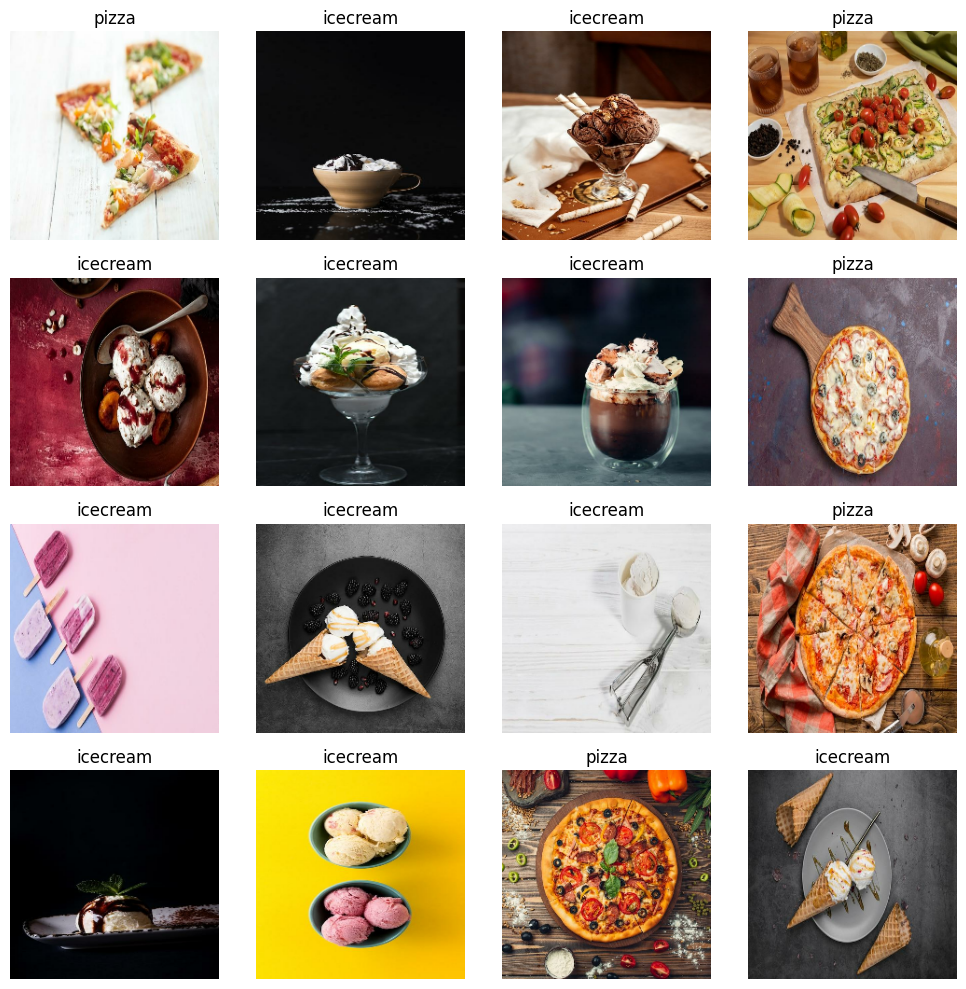

In [10]:
classes = train_ds.class_names
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 10))

for i, (img, label) in enumerate(zip(images[:16], labels[:16])):
    plt.subplot(4, 4, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(classes[np.argmax(label)])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Building Model

In [11]:
model= Sequential()
model.add(Input((224,224,3)))

# Data augmentation
model.add(keras.layers.RandomRotation(0.1))
model.add(keras.layers.RandomZoom(0.1))
model.add(keras.layers.Rescaling(1./255))

# convolution block 1
model.add(Conv2D(filters=32,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2))

# convolution block 2
model.add(Conv2D(filters=64,kernel_size=(3,3),strides=1,padding='valid',activation ='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2))

# convolution block 3
model.add(Conv2D(filters=128,kernel_size=(3,3),strides=1,padding='valid',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2))

# Classification Layers
model.add(Flatten())

model.add(Dense(units=128,activation='relu'))
model.add(Dense(units=64,activation='relu'))

# Output layer
model.add(Dense(units=2,activation='softmax'))

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,346 (42.64 MB)

 Trainable params: 11,177,346 (42.64 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Model Compilation
model.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy'])

In [15]:
# Define Callbacks
early_stopping = EarlyStopping(
      monitor='val_loss',
      patience=10,
      restore_best_weights=True,
      verbose=1
      )

# Model checkpoint to save the best model
checkpoint = ModelCheckpoint(
    "pizza.keras",
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [17]:
# Training model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping,checkpoint]
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8522 - loss: 0.3212
Epoch 1: val_loss did not improve from 0.22824
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.8522 - loss: 0.3212 - val_accuracy: 0.8462 - val_loss: 0.3776
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8643 - loss: 0.3104
Epoch 2: val_loss did not improve from 0.22824
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.8643 - loss: 0.3104 - val_accuracy: 0.9091 - val_loss: 0.2312
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8991 - loss: 0.2518
Epoch 3: val_loss did not improve from 0.22824
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.8991 - loss: 0.2518 - val_accuracy: 0.8881 - val_loss: 0.2769
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8748 - loss: 0.2920
Epoch 4: val_loss improved from 0.22824 to 0.22538, saving model to pizza.keras

Epoch 4: finished saving model to pizza.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step - a

In [18]:
# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9434 - loss: 0.1022
Test Loss: 0.10224094986915588
Test Accuracy: 0.9433962106704712


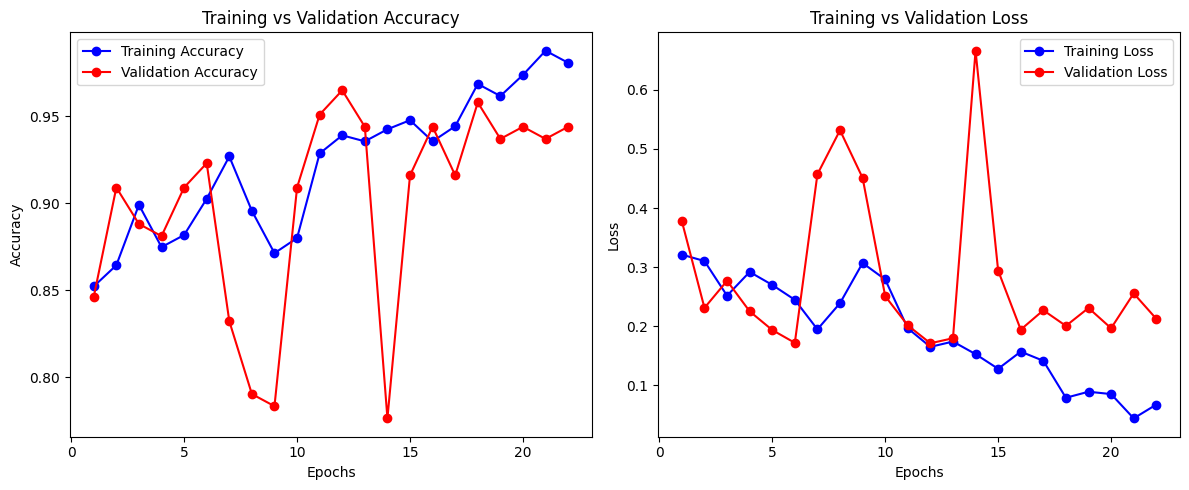

In [19]:
# Training and Validation Performance Visualization
acc = history.history['accuracy']
loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

# Number of epochs
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo-', label='Training Loss')
plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

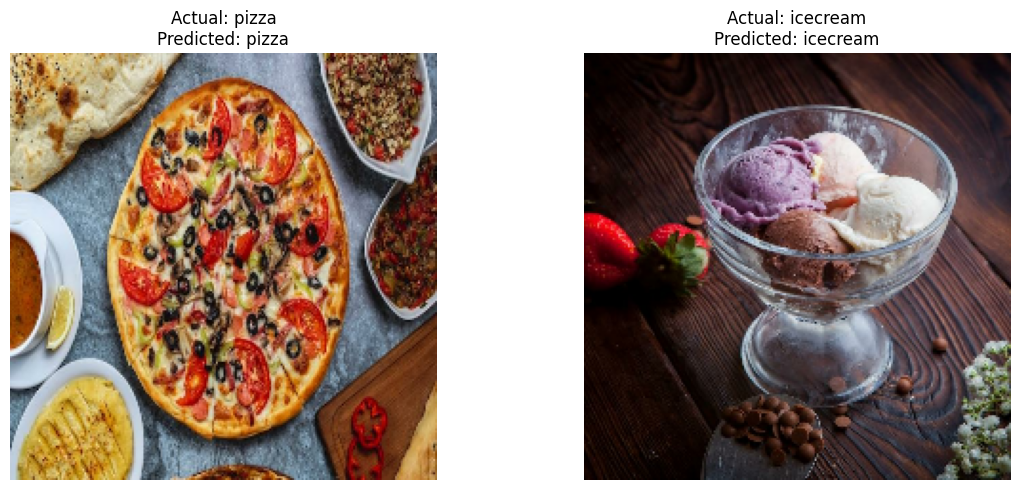

In [33]:

# Get one batch of test images
images, labels = next(iter(test_ds))

# Predict
predictions = model.predict(images, verbose=0)

# Get class names
class_names = train_ds.class_names

# Display only two images side by side
plt.figure(figsize=(12, 5))

for i in range(2):
    actual_label = class_names[np.argmax(labels[i])]
    predicted_label = class_names[np.argmax(predictions[i])]

    plt.subplot(1, 2, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"Actual: {actual_label}\nPredicted: {predicted_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()